# 05 · Comparativa de algoritmos de clustering

En el reto 3 segmentamos a los clientes con K-Means y k=7. Ahora la pregunta es: **¿lo habríamos hecho mejor con otro algoritmo?** Y, sobre todo, **¿saldrían los mismos segmentos?** Si con otro método los grupos cambian por completo, las campañas del reto 4 dependerían de una elección técnica y no de los clientes.

Lo que pide el reto:

1. Entrenar al menos otro algoritmo con **el mismo k y los mismos datos** preparados.
2. Comparar el **silhouette** de todos.
3. Analizar si los **segmentos cambian** de forma significativa.
4. Un **gráfico comparativo** de rendimiento, una tabla de métricas y una **conclusión razonada**.

Comparamos K-Means con tres alternativas: dos variantes de **Gaussian Mixture** y **Agglomerative Clustering**. Como extra, probamos **DBSCAN**, que funciona de forma muy distinta.

Como en el resto de notebooks, lo que afirmamos en el texto va respaldado por una tabla o un `assert`.

In [1]:
import sys
import time
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import DBSCAN, AgglomerativeClustering, KMeans
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score, davies_bouldin_score,
                             normalized_mutual_info_score, silhouette_score)
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestCentroid, NearestNeighbors

from src import config, clean, clustering
from src import pipeline as pl
from src.segmentos import SEGMENTOS

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")
FIG = config.FIG_DIR  # todas las figuras se guardan en outputs/figuras
FIG.mkdir(parents=True, exist_ok=True)

K = config.K_FINAL
DESTACADO, RESTO = config.SEGMENT_COLORS[0], config.BASE_GRAY  # K-Means en azul, las alternativas en gris

## 1. Los mismos datos que el K-Means final

Partimos de la tabla de clientes y la pasamos por el mismo pipeline del reto 2: 28 features, ya imputadas, con logaritmo, recortadas y escaladas. Todos los algoritmos reciben exactamente esta matriz `X` y el mismo k=7.

Como referencia, reentrenamos el K-Means del reto 3 con el mismo pipeline y la misma semilla. Comprobamos que da el mismo reparto que allí, y le ponemos a cada segmento el nombre que le dimos en el reto 4.

In [2]:
if config.CLIENTS_PKL.exists():
    clientes = clean.load_clients()
else:
    clientes = clean.build_client_table(clean.load_raw())

prep = pl.build_preprocessor()
X = prep.fit_transform(clientes)
nombres = list(prep.get_feature_names_out())

modelo_km = pl.build_pipeline(K).fit(clientes)
km = clustering.relabel_by_size(modelo_km.named_steps["kmeans"].labels_)

# El mismo reparto que en el reto 3 (notebook 03)
assert np.bincount(km).tolist() == [41811, 31769, 31611, 27575, 15660, 15327, 9703]
if config.LABELS_FINAL.exists():
    assert (clustering.load_labels().reindex(clientes.index).values == km).all()

SEG = {i: s["nombre"] for i, s in SEGMENTOS.items()}
print("X:", X.shape, "| k =", K)
pd.Series(np.bincount(km), index=[f"{i} · {SEG[i]}" for i in range(K)], name="clientes").to_frame()

X: (173456, 28) | k = 7


,clientes
0 · Coche en garantía,41811
1 · Recién llegados,31769
2 · Coche veterano,31611
3 · Electrificados,27575
4 · Desconectados,15660
5 · Multivehículo,15327
6 · Zonas premium,9703


## 2. Los algoritmos que comparamos

Elegimos algoritmos que **parten a los clientes de formas distintas** a K-Means, para que la comparación diga algo:

| Algoritmo | Cómo agrupa | Por qué lo probamos |
|---|---|---|
| **K-Means** (referencia) | Cada cliente va al centroide más cercano. Busca grupos compactos y de tamaño parecido | Es el modelo del reto 3 |
| **GMM diagonal** | Supone que cada grupo es una "nube" con forma de campana y asigna a cada cliente una probabilidad de pertenecer a cada nube. Cada variable tiene su propia dispersión dentro de cada grupo | Permite grupos más anchos en unas variables que en otras |
| **GMM completo** | Lo mismo, pero además cada nube puede estar inclinada: tiene en cuenta cómo se relacionan las variables entre sí dentro de cada grupo | Es el modelo más flexible: si los grupos tienen formas raras, debería verlas |
| **Agglomerative (Ward)** | Empieza con cada cliente en su propio grupo y va uniendo los dos grupos más parecidos hasta que quedan 7 | No depende de una semilla y produce una jerarquía de grupos |
| **DBSCAN** | Busca zonas densas de clientes; lo que queda lejos de cualquier zona densa es "ruido" | No necesita k. Sirve para ver si hay grupos naturales muy marcados |

Dos detalles prácticos:

- **Agglomerative no cabe en memoria con 173.456 clientes**: necesita la distancia entre cada par de clientes, unos 15.000 millones de números (más de 100 GB). Lo entrenamos sobre una **submuestra de 10.000 clientes** y después asignamos a cada uno de los demás al grupo cuyo centro tiene más cerca. Así obtenemos un segmento para todos y podemos compararlo con el resto.
- **GMM y K-Means se entrenan con todos los clientes.** Igual que en el reto 3, GMM se lanza varias veces (`n_init=3`) y nos quedamos con el mejor resultado.

In [3]:
SUBMUESTRA_AGG = np.random.default_rng(config.RANDOM_STATE).choice(len(X), 10_000, replace=False)


def agglomerative(sub):
    """Ward sobre una submuestra; el resto de clientes va al centro más cercano."""
    propias = AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(X[sub])
    return propias, NearestCentroid().fit(X[sub], propias).predict(X)


entrenar = {
    "K-Means": lambda s: KMeans(n_clusters=K, n_init=10, random_state=s).fit_predict(X),
    "GMM diagonal": lambda s: GaussianMixture(K, covariance_type="diag", n_init=3, random_state=s).fit(X).predict(X),
    "GMM completo": lambda s: GaussianMixture(K, covariance_type="full", n_init=3, random_state=s).fit(X).predict(X),
    "Agglomerative (Ward)": lambda s: agglomerative(SUBMUESTRA_AGG if s == config.RANDOM_STATE
                                                    else np.random.default_rng(s).choice(len(X), 10_000, replace=False))[1],
}

etiquetas, segundos = {}, {}
for nombre, f in entrenar.items():
    t0 = time.perf_counter()
    etiquetas[nombre] = clustering.relabel_by_size(f(config.RANDOM_STATE))
    segundos[nombre] = time.perf_counter() - t0
    print(f"{nombre:22s} {segundos[nombre]:5.1f} s")

assert adjusted_rand_score(etiquetas["K-Means"], km) == 1  # el mismo K-Means que el reto 3
ALGOS = list(etiquetas)

K-Means                  1.6 s


GMM diagonal             5.5 s


GMM completo            27.6 s


Agglomerative (Ward)     3.3 s


## 3. Métricas de calidad

Para cada algoritmo calculamos:

- **Silhouette** (más alto, mejor): lo bien separado que está cada cliente de los demás grupos, como en el reto 3. Lo calculamos sobre **la misma muestra de 20.000 clientes para todos** (`clustering.sample_index`), así la comparación es justa.
- **Davies-Bouldin** (más bajo, mejor): lo disperso que está cada grupo en relación con lo lejos que queda su vecino más parecido.
- **Calinski-Harabasz** (más alto, mejor): la separación entre grupos dividida por la dispersión dentro de ellos.
- **Tamaño del grupo más pequeño y del más grande**: para marketing, un grupo del 1 % es un nicho y uno del 50 % no segmenta.
- **Tiempo de entrenamiento**.

Davies-Bouldin y Calinski-Harabasz son baratos de calcular y los calculamos con todos los clientes.

In [4]:
idx = clustering.sample_index(len(X))

metricas = pd.DataFrame({
    nombre: {
        "silhouette": silhouette_score(X[idx], L[idx]),
        "davies_bouldin": davies_bouldin_score(X, L),
        "calinski_harabasz": calinski_harabasz_score(X, L),
        "grupo_min_%": np.bincount(L).min() / len(L) * 100,
        "grupo_max_%": np.bincount(L).max() / len(L) * 100,
        "segundos": segundos[nombre],
    }
    for nombre, L in etiquetas.items()
}).T
metricas.round(3)

,silhouette,davies_bouldin,calinski_harabasz,grupo_min_%,grupo_max_%,segundos
K-Means,0.129,1.817,19020.142,5.594,24.105,1.588
GMM diagonal,0.053,3.530,8015.440,3.894,37.589,5.468
GMM completo,0.026,4.356,6183.179,1.442,49.771,27.575
Agglomerative (Ward),0.122,1.823,18673.759,5.398,25.180,3.333


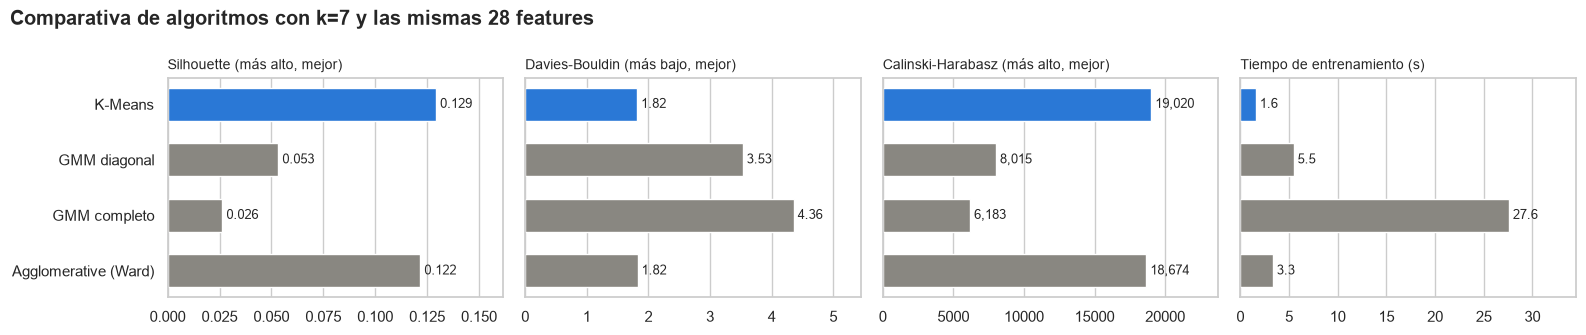

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4), sharey=True)
paneles = [("silhouette", "Silhouette (más alto, mejor)", "{:.3f}"),
           ("davies_bouldin", "Davies-Bouldin (más bajo, mejor)", "{:.2f}"),
           ("calinski_harabasz", "Calinski-Harabasz (más alto, mejor)", "{:,.0f}"),
           ("segundos", "Tiempo de entrenamiento (s)", "{:.1f}")]
colores = [DESTACADO if a == "K-Means" else RESTO for a in ALGOS]
for ax, (col, titulo, fmt) in zip(axes, paneles):
    ax.barh(ALGOS, metricas.loc[ALGOS, col], color=colores, height=0.6)
    for i, v in enumerate(metricas.loc[ALGOS, col]):
        ax.text(v, i, " " + fmt.format(v), va="center", fontsize=9)
    ax.set_title(titulo, loc="left", fontsize=10)
    ax.margins(x=0.25)
    ax.grid(axis="y", visible=False)
axes[0].invert_yaxis()
fig.suptitle(f"Comparativa de algoritmos con k={K} y las mismas 28 features", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.savefig(FIG / "05_metricas.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
# Lo que afirmamos en el texto de abajo
mejor = metricas.silhouette.idxmax()
assert mejor == "K-Means"
assert metricas.davies_bouldin.idxmin() == "K-Means" and metricas.calinski_harabasz.idxmax() == "K-Means"
assert (metricas.loc[["GMM diagonal", "GMM completo"], "silhouette"] < metricas.loc["Agglomerative (Ward)", "silhouette"]).all()
print("Ranking por silhouette:", " > ".join(metricas.silhouette.sort_values(ascending=False).index))

Ranking por silhouette: K-Means > Agglomerative (Ward) > GMM diagonal > GMM completo


**K-Means gana en las tres métricas de calidad.** Agglomerative queda cerca (en Davies-Bouldin están prácticamente empatados) y los dos GMM, bastante lejos.

Hay que leer bien a los GMM. El silhouette y Davies-Bouldin miden distancias y premian grupos "redondos" y compactos, que es justo lo que busca K-Means. GMM busca otra cosa: nubes de probabilidad que pueden ser alargadas o solaparse. Así que estas métricas le penalizan por diseño. Aun así, para marketing sí nos importa que los grupos estén separados: dos segmentos que se solapan mucho acaban recibiendo campañas casi iguales.

### Agglomerative: ¿cuánto le ayuda la submuestra?

Agglomerative se entrena con 10.000 clientes y el resto se asigna al centro más cercano. Ese segundo paso es, en el fondo, un paso de K-Means, así que puede "maquillar" su resultado. Para verlo, comparamos los dos algoritmos **sobre esos mismos 10.000 clientes**, con las etiquetas que da Ward directamente:

In [7]:
propias, _ = agglomerative(SUBMUESTRA_AGG)
s = SUBMUESTRA_AGG
mismos_10k = pd.Series({
    "K-Means (entrenado con todos)": silhouette_score(X[s], km[s]),
    "Agglomerative (sus etiquetas de Ward)": silhouette_score(X[s], propias),
    "Agglomerative (tras asignar por centro)": silhouette_score(X[s], etiquetas["Agglomerative (Ward)"][s]),
}, name="silhouette en la submuestra de 10.000").round(3)
assert mismos_10k.iloc[1] < mismos_10k.iloc[2] < mismos_10k.iloc[0]
mismos_10k.to_frame()

,silhouette en la submuestra de 10.000
K-Means (entrenado con todos),0.128
Agglomerative (sus etiquetas de Ward),0.084
Agglomerative (tras asignar por centro),0.121


Con sus propias etiquetas, Ward queda bastante por debajo de K-Means. Asignar por el centro más cercano le sube el silhouette, pero sigue sin alcanzarlo. Así que la ventaja de K-Means no es un efecto de cómo hemos extendido Agglomerative a todos los clientes.

## 4. Estabilidad: ¿sale lo mismo si repetimos?

En el reto 3 vimos que esto es lo que más importa: un segmento que cambia cada vez que reentrenamos no sirve para montar campañas. Medimos con el **ARI** cuánto se parece cada repetición al resultado original de ese mismo algoritmo (1 = agrupa exactamente igual; 0 = coincide lo mismo que por azar).

Hacemos **dos pruebas**, porque no todos los algoritmos se pueden repetir igual:

- **Prueba 1 · otra semilla, todos los clientes** (3 semillas). Mide si el resultado depende de por dónde empieza el algoritmo. Agglomerative no tiene semilla (con los mismos datos da siempre lo mismo), así que no entra.
- **Prueba 2 · otra submuestra** (5 submuestras de 10.000 clientes). **Todos los algoritmos** se entrenan con 10.000 clientes distintos cada vez y después asignan a toda la base. Es la misma prueba para los cuatro, y la más dura: cambian a la vez los datos y el punto de partida. Es lo que le pasa a Agglomerative siempre, así que es la comparación justa.

In [8]:
REPETICIONES_SEMILLA = [1, 2, 3]
REPETICIONES_SUB = [1, 2, 3, 4, 5]
submuestra = lambda s: np.random.default_rng(s).choice(len(X), 10_000, replace=False)
modelos = {
    "K-Means": lambda s: KMeans(n_clusters=K, n_init=10, random_state=s),
    "GMM diagonal": lambda s: GaussianMixture(K, covariance_type="diag", n_init=3, random_state=s),
    "GMM completo": lambda s: GaussianMixture(K, covariance_type="full", n_init=3, random_state=s),
}


def entrenar_en_submuestra(nombre, s):
    sub = submuestra(s)
    if nombre == "Agglomerative (Ward)":
        return agglomerative(sub)[1]
    return modelos[nombre](s).fit(X[sub]).predict(X)


semilla = pd.DataFrame({n: [adjusted_rand_score(etiquetas[n], entrenar[n](s)) for s in REPETICIONES_SEMILLA]
                        for n in modelos}).T
sub_ari = pd.DataFrame({n: [adjusted_rand_score(etiquetas[n], entrenar_en_submuestra(n, s)) for s in REPETICIONES_SUB]
                        for n in ALGOS}).T

estabilidad = pd.DataFrame({
    "semilla: media": semilla.mean(axis=1), "semilla: mínimo": semilla.min(axis=1),
    "submuestra: media": sub_ari.mean(axis=1), "submuestra: mínimo": sub_ari.min(axis=1),
}).reindex(ALGOS)

# Lo que afirmamos en el texto de abajo
assert estabilidad.loc["K-Means", "semilla: mínimo"] > 0.99
for col in estabilidad.columns:
    assert estabilidad[col].idxmax() == "K-Means"
assert estabilidad.loc["K-Means", "submuestra: mínimo"] > 0.9
assert (estabilidad.drop("K-Means")["submuestra: media"] < 0.8).all()
estabilidad.round(3)

,semilla: media,semilla: mínimo,submuestra: media,submuestra: mínimo
K-Means,0.997,0.992,0.952,0.933
GMM diagonal,0.507,0.311,0.687,0.384
GMM completo,0.722,0.649,0.701,0.514
Agglomerative (Ward),NaN,NaN,0.757,0.630


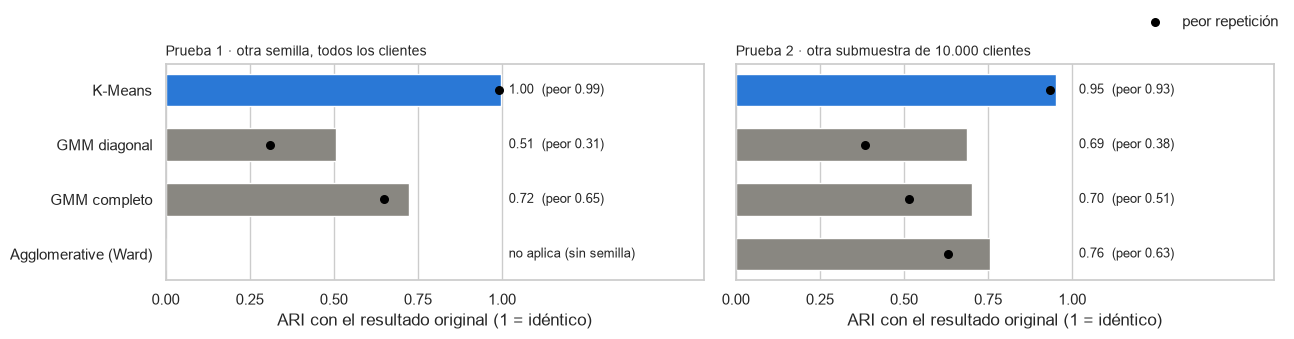

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.2), sharey=True)
for ax, prueba in zip(axes, ["semilla", "submuestra"]):
    media, minimo = estabilidad[f"{prueba}: media"], estabilidad[f"{prueba}: mínimo"]
    ax.barh(ALGOS, media.fillna(0), color=colores, height=0.6)
    ax.scatter(minimo, range(len(ALGOS)), color="black", s=30, zorder=3, label="peor repetición")
    for i, (m, mn) in enumerate(zip(media, minimo)):
        ax.text(1.02, i, "no aplica (sin semilla)" if np.isnan(m) else f"{m:.2f}  (peor {mn:.2f})",
                va="center", fontsize=9)
    ax.set_xlim(0, 1.6)
    ax.set_xticks([0, 0.25, 0.5, 0.75, 1])
    ax.grid(axis="y", visible=False)
    ax.set_title({"semilla": "Prueba 1 · otra semilla, todos los clientes",
                  "submuestra": "Prueba 2 · otra submuestra de 10.000 clientes"}[prueba], loc="left", fontsize=10)
    ax.set_xlabel("ARI con el resultado original (1 = idéntico)")
axes[0].invert_yaxis()
fig.legend(*axes[1].get_legend_handles_labels(), frameon=False, loc="upper right", bbox_to_anchor=(1, 1.08))
plt.tight_layout()
plt.savefig(FIG / "05_estabilidad.png", dpi=150, bbox_inches="tight")
plt.show()

**K-Means es el más estable en las dos pruebas:**

- **Con otra semilla da prácticamente el mismo resultado** (ARI de 0,99 o más). Los GMM no: tienen muchas soluciones casi igual de buenas, y la que sale depende de por dónde empiecen.
- **Con otra submuestra, K-Means también cambia, pero poco**: un ARI medio de 0,95 y nunca por debajo de 0,9. Es la prueba justa, la misma para los cuatro, y las alternativas se quedan en una media de entre 0,69 y 0,76, con repeticiones bastante peores.

Esto pesa mucho en la decisión: aunque un algoritmo tuviera mejor silhouette, si sus segmentos cambian cada vez que lo reentrenamos no podemos basar campañas en ellos. La prueba 2 es un adelanto del **Jackknife** (reto avanzado 3), que estudiará la estabilidad de K-Means con más detalle: qué segmentos y qué clientes cambian.

## 5. ¿Cambian los segmentos?

Que dos algoritmos tengan métricas parecidas no quiere decir que agrupen igual. Lo medimos de tres formas:

- **ARI** y **NMI** entre cada algoritmo y K-Means (1 = mismos grupos; 0 = nada que ver).
- **% de clientes en el mismo segmento**: emparejamos cada grupo del otro algoritmo con el segmento de K-Means con el que más clientes comparte (de uno en uno, sin repetir) y contamos cuántos clientes quedan en su pareja. Es la cifra más fácil de explicar a marketing.
- La **matriz de contingencia**: de cada segmento de K-Means, a qué grupo del otro algoritmo va cada cliente.

In [10]:
def emparejar(ref, otro):
    """Empareja los grupos de `otro` con los de `ref` maximizando los clientes en común."""
    tabla = pd.crosstab(ref, otro)
    filas, cols = linear_sum_assignment(-tabla.values)
    return dict(zip(tabla.columns[cols], tabla.index[filas])), tabla.values[filas, cols].sum() / len(ref)


parecido = pd.DataFrame({
    nombre: {"ARI": adjusted_rand_score(km, L), "NMI": normalized_mutual_info_score(km, L),
             "% mismo segmento": emparejar(km, L)[1] * 100}
    for nombre, L in etiquetas.items() if nombre != "K-Means"
}).T
assert parecido.ARI.idxmax() == "Agglomerative (Ward)"
parecido.round(3)

,ARI,NMI,% mismo segmento
GMM diagonal,0.264,0.357,46.459
GMM completo,0.199,0.273,40.288
Agglomerative (Ward),0.702,0.761,86.574


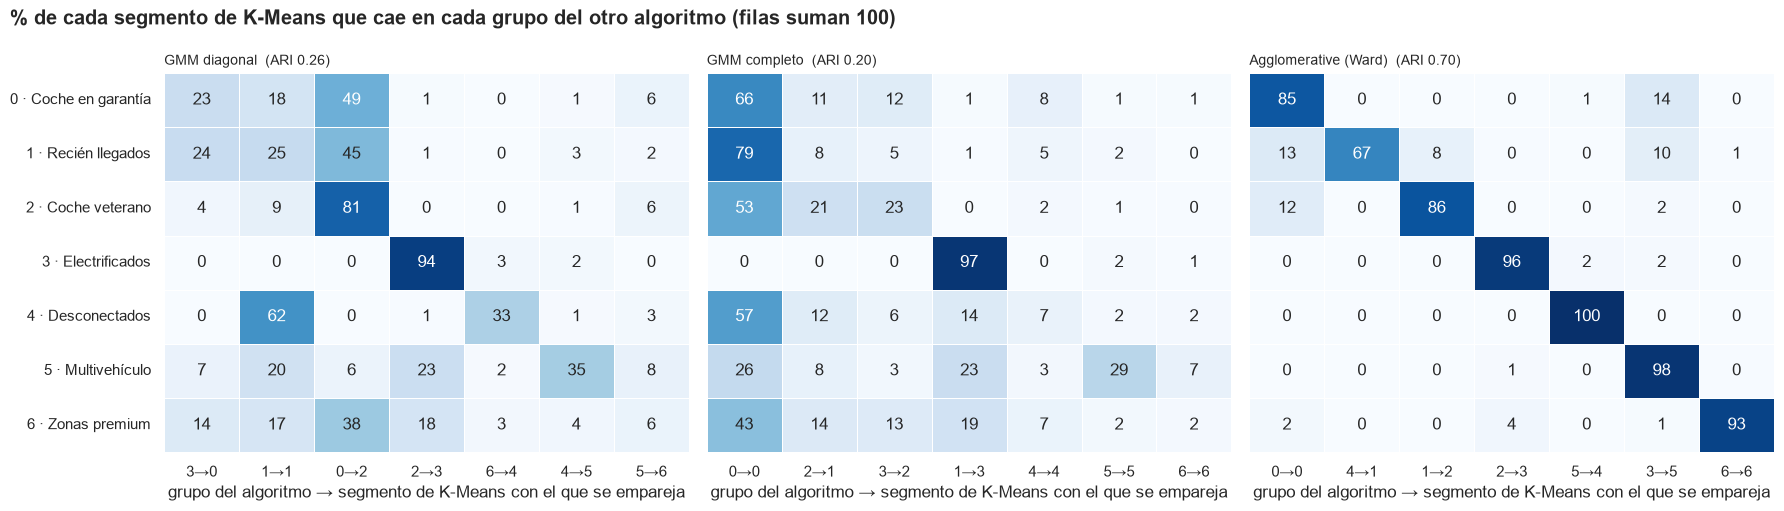

In [11]:
alternativas = [a for a in ALGOS if a != "K-Means"]
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2), sharey=True)
filas = [f"{i} · {SEG[i]}" for i in range(K)]
for ax, nombre in zip(axes, alternativas):
    pareja, _ = emparejar(km, etiquetas[nombre])
    # Columnas ordenadas por el segmento de K-Means con el que se emparejan: la diagonal = mismo segmento
    orden = sorted(pareja, key=pareja.get)
    tabla = pd.crosstab(km, etiquetas[nombre], normalize="index").reindex(columns=orden) * 100
    tabla.index = filas
    tabla.columns = [f"{c}→{pareja[c]}" for c in orden]
    sns.heatmap(tabla, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=100, cbar=False, linewidths=0.5, ax=ax)
    ax.set_title(f"{nombre}  (ARI {parecido.loc[nombre, 'ARI']:.2f})", loc="left", fontsize=10)
    ax.set_xlabel("grupo del algoritmo → segmento de K-Means con el que se empareja")
    ax.set_ylabel("")
fig.suptitle("% de cada segmento de K-Means que cae en cada grupo del otro algoritmo (filas suman 100)",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.savefig(FIG / "05_contingencia.png", dpi=150, bbox_inches="tight")
plt.show()

In [12]:
# Qué segmentos de K-Means conserva cada algoritmo: % de cada segmento que cae en su grupo emparejado
conserva = {}
for nombre in alternativas:
    pareja, _ = emparejar(km, etiquetas[nombre])
    inversa = {seg: grupo for grupo, seg in pareja.items()}
    conserva[nombre] = [(etiquetas[nombre][km == i] == inversa[i]).mean() * 100 for i in range(K)]
conserva = pd.DataFrame(conserva, index=filas).round(1)
# Lo que afirmamos en el texto de abajo
assert (conserva.loc[filas[3]] > 90).all()  # Electrificados: el mismo segmento con todos los algoritmos
assert conserva["Agglomerative (Ward)"].idxmin() == filas[1]  # Recién llegados: el que más cambia en Agglomerative
assert parecido.loc["Agglomerative (Ward)", "% mismo segmento"] > 80
conserva

,GMM diagonal,GMM completo,Agglomerative (Ward)
0 · Coche en garantía,23.4,65.8,84.9
1 · Recién llegados,25.2,7.8,67.3
2 · Coche veterano,80.9,22.8,86.1
3 · Electrificados,94.2,97.5,95.9
4 · Desconectados,33.0,7.1,99.9
5 · Multivehículo,35.5,29.2,97.9
6 · Zonas premium,6.4,2.2,92.7


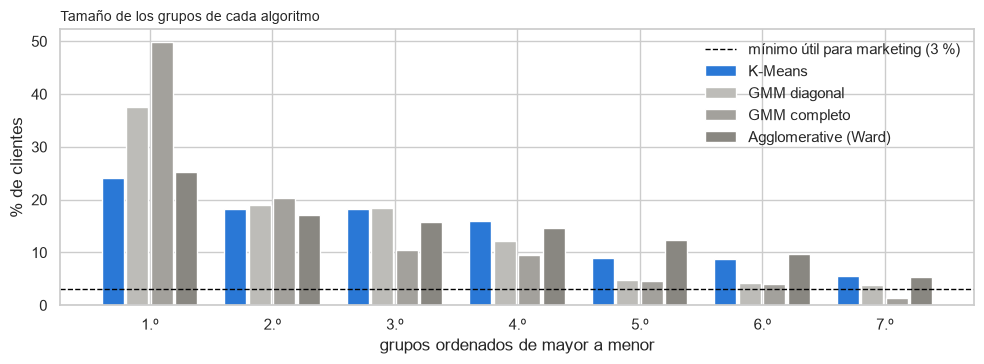

,K-Means,GMM diagonal,GMM completo,Agglomerative (Ward)
1.º,24.1,37.6,49.8,25.2
2.º,18.3,18.9,20.3,17.1
3.º,18.2,18.5,10.4,15.7
4.º,15.9,12.1,9.6,14.6
5.º,9.0,4.8,4.5,12.4
6.º,8.8,4.3,4.0,9.6
7.º,5.6,3.9,1.4,5.4


In [13]:
tamanos = pd.DataFrame({n: np.sort(np.bincount(L))[::-1] / len(L) * 100 for n, L in etiquetas.items()},
                       index=[f"{i + 1}.º" for i in range(K)])
fig, ax = plt.subplots(figsize=(10, 3.8))
x = np.arange(K)
ancho = 0.2
for j, nombre in enumerate(ALGOS):
    ax.bar(x + (j - 1.5) * ancho, tamanos[nombre], width=ancho * 0.9, label=nombre,
           color=DESTACADO if nombre == "K-Means" else sns.light_palette(RESTO, 5)[j + 1])
ax.set_xticks(x, tamanos.index)
ax.set_xlabel("grupos ordenados de mayor a menor")
ax.set_ylabel("% de clientes")
ax.axhline(3, color="black", linestyle="--", linewidth=1, label="mínimo útil para marketing (3 %)")
ax.legend(frameon=False)
ax.set_title("Tamaño de los grupos de cada algoritmo", loc="left", fontsize=10)
plt.tight_layout()
plt.savefig(FIG / "05_tamanos.png", dpi=150, bbox_inches="tight")
plt.show()
tamanos.round(1)

### ¿Qué separa cada algoritmo?

Para entender por qué cambian los segmentos miramos, en **unidades originales**, en qué se diferencian los grupos de cada algoritmo. Ponemos las variables que más usamos para describir los segmentos en el reto 4:

In [14]:
vars_perfil = ["n_vehicles", "share_plugin_ev", "n_connected_now", "main_vehicle_age",
               "tenure_months", "tenure_is_default", "workshop_visits_mean", "ppi"]


def perfil(L):
    g = clientes[vars_perfil].groupby(L)
    t = g.mean()
    t.insert(0, "% clientes", g.size() / len(L) * 100)
    return t.round(2)


perfiles = {nombre: perfil(L) for nombre, L in etiquetas.items()}
perfiles["GMM completo"]

,% clientes,n_vehicles,share_plugin_ev,n_connected_now,main_vehicle_age,tenure_months,tenure_is_default,workshop_visits_mean,ppi
0,49.77,1.27,0.00,0.94,4.79,32.84,0.00,2.10,46541.52
1,20.32,1.74,0.90,1.00,2.80,31.93,0.07,2.06,46017.44
2,10.41,1.51,0.00,1.06,6.51,34.46,0.22,1.89,48367.96
3,9.56,1.23,0.00,1.00,6.96,35.73,0.69,2.08,49117.88
4,4.52,1.48,0.00,0.88,4.28,37.20,0.33,2.96,52210.85
5,3.97,7.83,0.29,2.53,2.21,43.30,0.09,1.69,43699.15
6,1.44,7.38,0.35,1.42,3.55,45.89,0.07,2.25,56821.28


In [15]:
gmm = perfiles["GMM completo"]
grupo_36 = gmm.tenure_is_default.idxmax()
print(f"GMM completo, grupo {grupo_36}: {gmm.loc[grupo_36, '% clientes']:.1f} % de los clientes, "
      f"{gmm.loc[grupo_36, 'tenure_is_default']:.0%} con la antigüedad por defecto de 36 meses "
      f"(en toda la base: {clientes.tenure_is_default.mean():.0%})")
print(f"Su grupo más pequeño tiene el {gmm['% clientes'].min():.1f} % de los clientes")
print(f"En K-Means, el segmento con más antigüedad por defecto tiene un {perfiles['K-Means'].tenure_is_default.max():.0%}")
assert gmm.loc[grupo_36, "tenure_is_default"] > 0.5 and perfiles["K-Means"].tenure_is_default.max() < 0.3

GMM completo, grupo 3: 9.6 % de los clientes, 69% con la antigüedad por defecto de 36 meses (en toda la base: 12%)
Su grupo más pequeño tiene el 1.4 % de los clientes
En K-Means, el segmento con más antigüedad por defecto tiene un 27%


Aquí está la diferencia de fondo:

- **K-Means** reparte a los clientes según su relación con la marca: antigüedad, visitas en garantía, edad del coche, electrificación y número de vehículos. Son segmentos de tamaños parecidos que se pueden convertir en campañas.
- **GMM completo** dedica un grupo entero a los clientes con la **antigüedad por defecto de 36 meses**, que es justo el artefacto de carga que detectamos en el EDA. Al modelar la forma de cada nube, GMM se agarra a las variables binarias muy marcadas, aunque no digan nada del cliente. Además, mete casi a la mitad de la base en un único grupo y deja otro con poco más del 1 %.
- **GMM diagonal** se parece algo más a K-Means, pero solo conserva bien dos segmentos: Electrificados y Coche veterano. Los demás se reparten entre varios grupos, y uno de ellos es enorme (más de un tercio de los clientes).
- **Agglomerative** es el que más se parece a K-Means: casi 9 de cada 10 clientes quedan en el segmento equivalente. Conserva prácticamente intactos Desconectados, Multivehículo, Electrificados y Zonas premium. El que más cambia es **Recién llegados**: un tercio de sus clientes pasa a los grupos equivalentes a Coche en garantía, Multivehículo y Coche veterano. Es un segmento definido sobre todo por "poco tiempo con la marca y coche nuevo", y su frontera con los vecinos es la más discutible.
- **Electrificados es el mismo segmento con los cuatro algoritmos** (más del 90 % de sus clientes siguen juntos en todos). Es el hallazgo más robusto de la segmentación.

## 6. DBSCAN

DBSCAN no recibe k: busca zonas densas. Tiene dos parámetros:

- `min_samples`: cuántos vecinos necesita un cliente para estar en una zona densa. Usamos la regla habitual, el doble del número de features (56).
- `eps`: la distancia máxima a esos vecinos. La elegimos con el **gráfico de k-distancias**: ordenamos a los clientes por la distancia a su vecino número 56 y buscamos el punto donde la curva se dispara.

DBSCAN también compara todos con todos, así que lo ejecutamos sobre 10.000 clientes de la muestra fija.

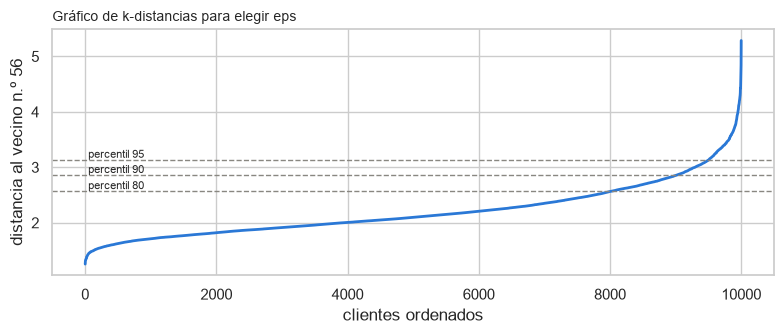

,eps,grupos,% ruido,% en el grupo mayor
percentil 80,2.56,3,5.62,85.70
percentil 90,2.85,1,2.25,97.75
percentil 95,3.13,1,0.65,99.35


In [16]:
MIN_SAMPLES = 2 * X.shape[1]
xs = X[idx[:10_000]]
kdist = np.sort(NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(xs).kneighbors(xs)[0][:, -1])

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(kdist, color=DESTACADO, linewidth=2)
for p in [80, 90, 95]:
    ax.axhline(np.percentile(kdist, p), color=RESTO, linestyle="--", linewidth=1)
    ax.text(0, np.percentile(kdist, p), f" percentil {p}", va="bottom", fontsize=8)
ax.set_xlabel("clientes ordenados")
ax.set_ylabel(f"distancia al vecino n.º {MIN_SAMPLES}")
ax.set_title("Gráfico de k-distancias para elegir eps", loc="left", fontsize=10)
plt.tight_layout()
plt.savefig(FIG / "05_dbscan_kdist.png", dpi=150, bbox_inches="tight")
plt.show()

dbscan = []
for p in [80, 90, 95]:
    eps = np.percentile(kdist, p)
    L = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit_predict(xs)
    tam = np.bincount(L[L >= 0]) if (L >= 0).any() else np.array([0])
    dbscan.append({"eps": eps, "grupos": int((tam > 0).sum()), "% ruido": (L < 0).mean() * 100,
                   "% en el grupo mayor": tam.max() / len(L) * 100})
dbscan = pd.DataFrame(dbscan, index=["percentil 80", "percentil 90", "percentil 95"]).round(2)
assert (dbscan["% en el grupo mayor"] > 80).all() and dbscan.loc["percentil 95", "% en el grupo mayor"] > 95
dbscan

La curva sube de forma suave hasta el 95 % de los clientes y solo se dispara al final: el codo está hacia el percentil 95, y lo que hay a su derecha son clientes aislados. Eso ya dice mucho: **no hay zonas densas separadas entre sí**, sino una única masa de clientes más o menos uniforme. Con el `eps` del codo, DBSCAN mete al 99 % de los clientes en un solo grupo; bajando `eps` solo consigue más ruido, no más segmentos. Encaja con lo que vimos en el reto 3: los clientes forman un continuo y no islas. DBSCAN no sirve para este problema, ni puede darnos 7 segmentos para comparar, así que no lo incluimos en las tablas de arriba.

## 7. Limitaciones de esta comparativa

Antes de concluir, conviene ser honestos con lo que esta comparación **no** demuestra:

1. **Las métricas juegan en el campo de K-Means.** El silhouette, Davies-Bouldin y Calinski-Harabasz miden distancias a centros, que es justo lo que optimiza K-Means. Además, las features se eligieron en el reto 3 mirando el silhouette de K-Means (por ejemplo, quitamos la población porque lo empeoraba). Así que parte de su ventaja en estas métricas viene de cómo está montado el problema. Por eso no decidimos solo por ellas: la estabilidad (prueba 2, la misma para todos) y el sentido de negocio de los grupos no dependen de eso.
2. **GMM no está hecho para nuestros datos.** Supone que cada grupo es una nube con forma de campana, y 20 de nuestras 28 columnas son 0/1. Que salga peor era previsible. Un algoritmo pensado para datos mixtos (numéricos y categóricos), como k-prototypes, sería una alternativa más justa; no lo probamos porque necesita una librería que no está en el proyecto.
3. **La diferencia con Agglomerative en silhouette es pequeña** (0,129 frente a 0,122) y, con valores tan bajos en todos los algoritmos, por sí sola no decidiría nada. Lo que desempata es la estabilidad y que Agglomerative no escala a toda la base.
4. **El parecido entre Agglomerative y K-Means está algo inflado.** Para dar segmento a toda la base asignamos cada cliente al centro más cercano, que es un paso de K-Means, así que lo acerca a K-Means. Con las etiquetas que da Ward directamente, sobre su submuestra, se parecen bastante menos:

In [17]:
parecido_propias = pd.Series({
    "Ward, sus propias etiquetas (10.000 clientes)": adjusted_rand_score(km[SUBMUESTRA_AGG], propias),
    "Ward, tras asignar por centro (todos los clientes)": parecido.loc["Agglomerative (Ward)", "ARI"],
}, name="ARI con K-Means").round(3)
assert parecido_propias.iloc[0] < parecido_propias.iloc[1]
assert (parecido.loc[["GMM diagonal", "GMM completo"], "ARI"] < parecido_propias.iloc[0]).all()
parecido_propias.to_frame()

,ARI con K-Means
"Ward, sus propias etiquetas (10.000 clientes)",0.486
"Ward, tras asignar por centro (todos los clientes)",0.702


Aun así, ninguna de estas limitaciones cambia la recomendación: en las pruebas que no dependen de la geometría de K-Means (estabilidad con submuestras, tamaño y sentido de los grupos), K-Means sigue siendo la mejor opción.

## 8. Conclusión: ¿qué algoritmo usamos?

In [18]:
resumen = pd.DataFrame({
    "silhouette": metricas.silhouette,
    "Davies-Bouldin": metricas.davies_bouldin,
    "estabilidad semilla (peor ARI)": estabilidad["semilla: mínimo"],
    "estabilidad submuestra (ARI medio)": estabilidad["submuestra: media"],
    "parecido a K-Means (ARI)": parecido.ARI.reindex(ALGOS).fillna(1.0),
    "grupo más pequeño (%)": metricas["grupo_min_%"],
    "grupo más grande (%)": metricas["grupo_max_%"],
    "tiempo (s)": metricas.segundos,
}).round(3)
resumen

,silhouette,Davies-Bouldin,estabilidad semilla (peor ARI),estabilidad submuestra (ARI medio),parecido a K-Means (ARI),grupo más pequeño (%),grupo más grande (%),tiempo (s)
K-Means,0.129,1.817,0.992,0.952,1.000,5.594,24.105,1.588
GMM diagonal,0.053,3.530,0.311,0.687,0.264,3.894,37.589,5.468
GMM completo,0.026,4.356,0.649,0.701,0.199,1.442,49.771,27.575
Agglomerative (Ward),0.122,1.823,NaN,0.757,0.702,5.398,25.180,3.333


| Criterio | K-Means | GMM diagonal | GMM completo | Agglomerative (Ward) |
|---|---|---|---|---|
| Separación (silhouette, Davies-Bouldin) | **La mejor** | Baja | La peor | Cerca de K-Means, pero peor con sus propias etiquetas |
| Estabilidad al repetir | **Prácticamente idéntico con otra semilla; casi igual con otra submuestra** | Cambia mucho | Cambia | Cambia con la submuestra |
| Tamaño de los grupos | Equilibrado | Un grupo enorme | Un grupo de casi la mitad y otro de ~1 % | Equilibrado |
| Qué separa | Relación con la marca | Mezcla segmentos | Se agarra a un artefacto de los datos (antigüedad por defecto) | Parecido a K-Means |
| Escala a toda la base (173.456 clientes) | Sí, en segundos | Sí | Sí, pero es el más lento | **No**: hay que usar una submuestra |
| Facilidad para explicarlo y aplicarlo a clientes nuevos | Centroide más cercano | Probabilidades | Probabilidades | Hay que inventar una regla para los clientes nuevos |

**Recomendación: mantenemos K-Means.** No es solo que tenga el silhouette más alto:

1. **Separa mejor** en las tres métricas, y la ventaja se mantiene cuando comparamos a Agglomerative con sus propias etiquetas.
2. **Es estable.** Da prácticamente los mismos segmentos con cualquier semilla, y casi los mismos aunque lo entrenemos con otros clientes. En la prueba justa (la misma para los cuatro) saca bastante ventaja a todas las alternativas. Es imprescindible para que marketing pueda planificar campañas sobre ellos (lo pondremos a prueba más a fondo con el Jackknife).
3. **Sus segmentos tienen sentido de negocio.** GMM completo dedica un grupo a un valor por defecto de carga, y los dos GMM crean grupos demasiado grandes o demasiado pequeños para usarlos.
4. **Es el más práctico:** entrena toda la base en segundos, y asignar un cliente nuevo es tan simple como buscar el centroide más cercano.

**Lo que nos dice la comparativa sobre los propios segmentos.** Agglomerative, que construye los grupos de una forma totalmente distinta (uniendo clientes de abajo arriba), deja a casi 9 de cada 10 clientes en el segmento equivalente. Esa cifra está algo inflada por la asignación al centro más cercano (limitación 4), pero aun con sus propias etiquetas el parecido es bastante mayor que el de los GMM. Es una buena señal de que los segmentos están en los datos y no son solo un efecto de K-Means. Para marketing:

- **Electrificados, Desconectados, Multivehículo y Zonas premium** salen casi iguales con otro algoritmo. Son segmentos sólidos sobre los que se pueden lanzar campañas específicas con confianza.
- **Recién llegados** es el que más depende del algoritmo. Su frontera con Coche en garantía y Coche veterano es difusa, así que las acciones para este segmento conviene que no dependan de una frontera exacta (por ejemplo, campañas de bienvenida por meses de antigüedad, más que por pertenecer al segmento).